## Part A — Lọc ảnh và làm sắc nét
Hai ảnh tự chụp (desk, setup); hai loại nhiễu; Mean, Gaussian, Median, Laplacian với nhiều tham số. Đánh giá PSNR, SSIM, MSE và thời gian (bảng tổng hợp = trung bình trên hai ảnh).

In [1]:
import time
from pathlib import Path
import cv2
import matplotlib
matplotlib.use("Agg")                    # chỉ ghi hình ra file, không mở cửa sổ
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity
KERNELS = [3, 5, 7]                      # kích thước kernel k x k
SIGMAS = [0.5, 1.0, 2.0]                 # độ lệch chuẩn thử cho Gaussian filter
ALPHAS = [0.5, 1.0]                      # độ mạnh làm sắc nét
NOISE_SIGMA = 20                         # độ lệch chuẩn nhiễu Gaussian (thang 0..255)
SP_DENSITY = 0.05                        # 5% pixel bị nhiễu muối tiêu
MAX_WIDTH = 1024                         # thu nhỏ ảnh quá lớn
def add_gaussian_noise(img, sigma, rng):
    """Add zero-mean Gaussian noise in float, then clip to [0, 255]."""
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
def add_salt_pepper(img, density, rng):
    """Set each pixel to 0 or 255, each with probability density / 2."""
    out = img.copy()
    r = rng.random(img.shape[:2])
    out[r < density / 2] = 0
    out[r > 1 - density / 2] = 255
    return out
def laplacian_sharpen(img, k, alpha):
    """I_sharp = I - alpha * Laplacian(I). The k x k OpenCV kernel is divided by its
    response to f = x^2 (true Laplacian = 2), so alpha has the same meaning for every k."""
    x = np.arange(-10, 11, dtype=np.float32)
    gain = cv2.Laplacian(np.tile(x ** 2, (21, 1)), cv2.CV_32F, ksize=k)[10, 10] / 2.0
    f = img.astype(np.float32)
    lap = cv2.Laplacian(f, cv2.CV_32F, ksize=k) / gain
    return np.clip(f - alpha * lap, 0, 255).astype(np.uint8)
def filter_configs():
    """List of (filter name, parameters, function) for every tested setting."""
    cfgs = [("Mean", f"{k}x{k}", lambda im, k=k: cv2.blur(im, (k, k))) for k in KERNELS]
    cfgs += [("Gaussian", f"{k}x{k}, sigma={s}", lambda im, k=k, s=s: cv2.GaussianBlur(im, (k, k), s))
             for k in KERNELS for s in SIGMAS]
    cfgs += [("Median", f"{k}x{k}", lambda im, k=k: cv2.medianBlur(im, k)) for k in KERNELS]
    cfgs += [("Laplacian sharpen", f"{k}x{k}, alpha={a}", lambda im, k=k, a=a: laplacian_sharpen(im, k, a))
             for k in KERNELS for a in ALPHAS]
    return cfgs
def metrics(clean, img):
    """PSNR, SSIM (colour, channel_axis=2) and MSE against the clean image."""
    return {"PSNR (dB)": peak_signal_noise_ratio(clean, img, data_range=255),
            "SSIM": structural_similarity(clean, img, channel_axis=2, data_range=255),
            "MSE": mean_squared_error(clean, img)}
def run_image(path, out_dir, rng):
    """Thử mọi bộ lọc trên hai loại nhiễu của một ảnh; trả về các dòng kết quả và lưu lưới ảnh."""
    clean = cv2.imread(str(path))
    if clean.shape[1] > MAX_WIDTH:
        clean = cv2.resize(clean, None, fx=MAX_WIDTH / clean.shape[1], fy=MAX_WIDTH / clean.shape[1],
                           interpolation=cv2.INTER_AREA)
    noisy = {"Gaussian": add_gaussian_noise(clean, NOISE_SIGMA, rng),
             "Salt&Pepper": add_salt_pepper(clean, SP_DENSITY, rng)}
    rows, best = [], {}
    for _, _, fn in filter_configs():                          # chạy khởi động: lần gọi đầu tiên luôn chậm hơn
        fn(clean)
    for noise, img in noisy.items():
        rows.append({"image": path.stem, "noise": noise, "filter": "None (noisy)", "params": "-",
                     **metrics(clean, img), "Time (ms)": 0.0})
        for name, params, fn in filter_configs():
            t0 = time.perf_counter()
            out = fn(img)
            ms = (time.perf_counter() - t0) * 1000
            m = metrics(clean, out)
            rows.append({"image": path.stem, "noise": noise, "filter": name, "params": params, **m, "Time (ms)": ms})
            # giữ kết quả có PSNR cao nhất của mỗi bộ lọc khử nhiễu để vẽ lưới ảnh
            if name != "Laplacian sharpen" and m["PSNR (dB)"] > best.get((noise, name), ("", None, -1))[2]:
                best[(noise, name)] = (params, out, m["PSNR (dB)"])
    save_grid(path.stem, clean, noisy, best, out_dir)
    return rows
def save_grid(name, clean, noisy, best, out_dir):
    """Lưới ảnh: mỗi hàng một loại nhiễu; cột = gốc, nhiễu, Mean / Gaussian / Median tốt nhất,
    và ảnh khử nhiễu tốt nhất sau khi làm sắc nét (Laplacian 3x3, alpha = 0.5)."""
    fig, axes = plt.subplots(len(noisy), 6, figsize=(19, 3.1 * len(noisy)))
    for r, (noise, img) in enumerate(noisy.items()):
        top = max(["Mean", "Gaussian", "Median"], key=lambda f: best[(noise, f)][2])   # bộ lọc tốt nhất
        panels = [("Original", clean), (f"Noisy ({noise})", img)]
        panels += [(f"{f} {best[(noise, f)][0]}", best[(noise, f)][1]) for f in ["Mean", "Gaussian", "Median"]]
        panels += [(f"{top} + Laplacian 3x3, alpha=0.5", laplacian_sharpen(best[(noise, top)][1], 3, 0.5))]
        for c, (title, im) in enumerate(panels):
            axes[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            axes[r, c].set_title(title, fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / f"{name}_grid.png", dpi=150)
    plt.close(fig)
def save_chart(summary, out_dir):
    """PSNR theo kích thước kernel cho Mean, Gaussian (sigma = 1) và Median, mỗi loại nhiễu một ô."""
    d = summary[summary["filter"].isin(["Mean", "Gaussian", "Median"])].copy()
    d = d[(d["filter"] != "Gaussian") | d["params"].str.endswith("sigma=1.0")]
    d["k"] = d["params"].str[0].astype(int)                      # "5x5, ..." -> 5
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, noise in zip(axes, ["Gaussian", "Salt&Pepper"]):
        for f in ["Mean", "Gaussian", "Median"]:
            s = d[(d["noise"] == noise) & (d["filter"] == f)]
            ax.plot(s["k"], s["PSNR (dB)"], marker="o", label=f)
        ax.set_title(f"{noise} noise")
        ax.set_xlabel("Kernel size k")
        ax.set_xticks(KERNELS)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("PSNR (dB)")
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(out_dir / "chart_psnr_vs_kernel.png", dpi=150)
    plt.close(fig)
out_dir = Path("results/part_a")
out_dir.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)                      # seed cố định -> nhiễu giống nhau mỗi lần chạy
images = sorted(p for p in Path("data/part_a").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
rows = []
for p in images:
    print(f"[Part A] {p.name}")
    rows += run_image(p, out_dir, rng)
df = pd.DataFrame(rows)
df.to_csv(out_dir / "metrics_all.csv", index=False)
# bảng tổng hợp: trung bình trên các ảnh, cho từng loại nhiễu / bộ lọc / tham số
summary = df.groupby(["noise", "filter", "params"], sort=False)[["PSNR (dB)", "SSIM", "MSE", "Time (ms)"]].mean()
summary.round(4).to_csv(out_dir / "metrics_summary.csv")
save_chart(summary.reset_index(), out_dir)
print(summary.round(3).to_string())

[Part A] desk.jpg


[Part A] setup.jpg


                                              PSNR (dB)   SSIM       MSE  Time (ms)
noise       filter            params                                               
Gaussian    None (noisy)      -                  22.395  0.436   374.672      0.000
            Mean              3x3                25.095  0.662   208.439      2.309
                              5x5                23.023  0.620   346.237      3.192
                              7x7                21.967  0.574   444.162      2.134
            Gaussian          3x3, sigma=0.5     25.614  0.569   178.598      0.892
                              3x3, sigma=1.0     26.021  0.690   166.947      1.312
                              3x3, sigma=2.0     25.311  0.671   198.036      0.617
                              5x5, sigma=0.5     25.614  0.569   178.598      0.925
                              5x5, sigma=1.0     25.553  0.711   188.383      0.853
                              5x5, sigma=2.0     23.729  0.663   292.625    

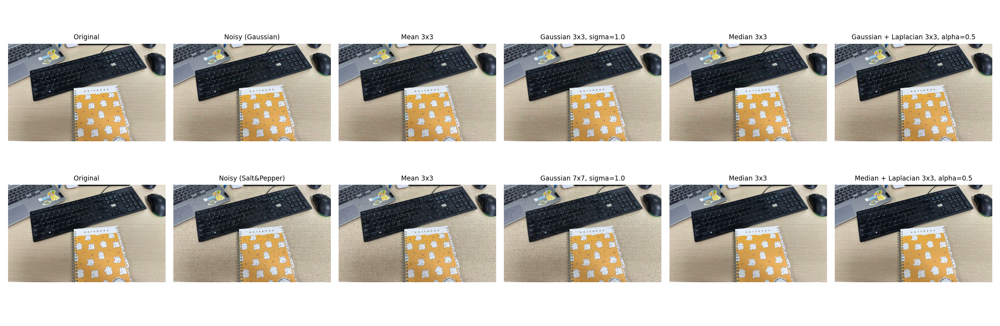

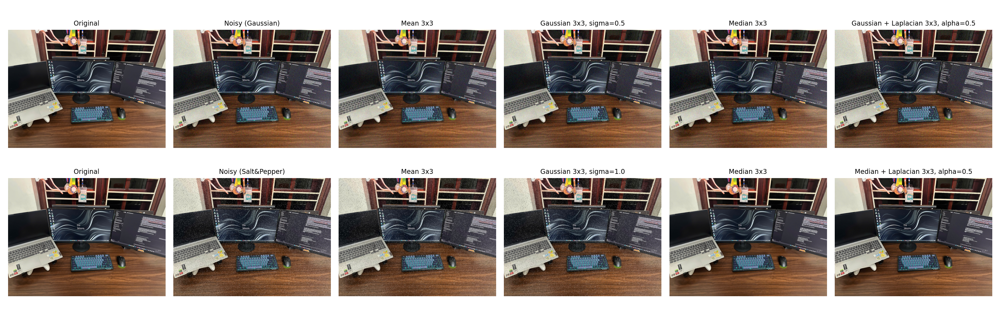

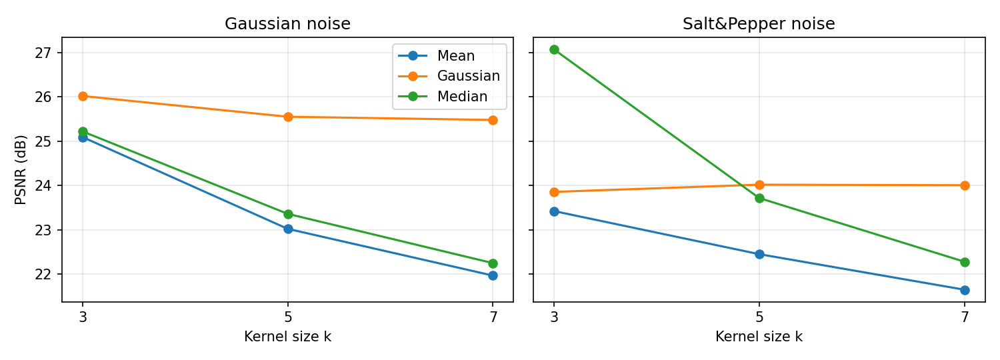

In [2]:
from IPython.display import display, Image
for name in ['desk_grid.png', 'setup_grid.png', 'chart_psnr_vs_kernel.png']:
    display(Image(filename=f"results/part_a/{name}", width=1000))

## Part B — Stereo và tái dựng 3D
SIFT + RANSAC để ước lượng F; so sánh BM/SGBM và tạo point cloud. Camera và offset giả định: point cloud minh họa, chưa bảo đảm hình dạng hay kích thước thực.

In [3]:
import time
from pathlib import Path
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
RATIO = 0.75                       # Lowe ratio test
RANSAC_THRESH = 1.0                # ngưỡng RANSAC cho F (px)
MIN_DISP = -16                     # disparity của Venus nằm trong [-7, 9.4] px nên cho phép giá trị âm
BLOCK_SIZES = [5, 9, 15, 21]
NUM_DISPS = [16, 32, 48, 64]       # numDisparities phải chia hết cho 16
# Camera giả định: point cloud minh họa, chưa bảo đảm hình dạng hoặc kích thước thực
FOCAL_PX = 420.0                   # tiêu cự ~ chiều rộng ảnh
BASELINE = 1.0                     # đơn vị tùy ý
DISP_OFFSET = 12.0                 # cx_phải - cx_trái giả định; Z = f*B/(d + offset)
def read_flo(path):
    """Đọc file .flo của Middlebury: số kiểm tra 202021.25, chiều rộng, chiều cao, rồi các cặp (u, v)."""
    with open(path, "rb") as f:
        assert np.fromfile(f, np.float32, 1)[0] == 202021.25, "not a .flo file"
        w, h = np.fromfile(f, np.int32, 2)
        data = np.fromfile(f, np.float32, 2 * w * h).reshape(h, w, 2)
    u = data[..., 0]
    return np.where(np.abs(u) < 1e9, -u, np.nan).astype(np.float32)   # giá trị ~1e9 = không có GT; d = -u
# 1. Fundamental matrix và epipolar line
def match_points(gl, gr):
    """SIFT + brute-force KNN (k=2) + Lowe ratio test; returns matched left/right points."""
    sift = cv2.SIFT_create()
    kp1, d1 = sift.detectAndCompute(gl, None)
    kp2, d2 = sift.detectAndCompute(gr, None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    good = [m for m, n in knn if m.distance < RATIO * n.distance]   # ratio test
    p1 = np.float32([kp1[m.queryIdx].pt for m in good])
    p2 = np.float32([kp2[m.trainIdx].pt for m in good])
    return p1, p2, len(kp1), len(kp2)
def epipolar_errors(F, p1, p2):
    """Symmetric point-to-epipolar-line distance and Sampson error (px) of each match."""
    x1 = np.c_[p1, np.ones(len(p1))]
    x2 = np.c_[p2, np.ones(len(p2))]
    l2 = x1 @ F.T                                  # epipolar lines in the right image: F x1
    l1 = x2 @ F                                    # epipolar lines in the left image: F^T x2
    num = np.sum(x2 * l2, axis=1)                  # x2^T F x1 (0 for a perfect match)
    d_epi = 0.5 * (np.abs(num) / np.hypot(l2[:, 0], l2[:, 1]) + np.abs(num) / np.hypot(l1[:, 0], l1[:, 1]))
    sampson = np.abs(num) / np.sqrt(l2[:, 0] ** 2 + l2[:, 1] ** 2 + l1[:, 0] ** 2 + l1[:, 1] ** 2)
    return d_epi, sampson
def fundamental_study(left, right, out_dir):
    """Ước lượng F bằng RANSAC, ghi sai số ra CSV và vẽ 15 epipolar line trên cả hai ảnh."""
    gl, gr = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
    p1, p2, n1, n2 = match_points(gl, gr)
    cv2.setRNGSeed(42)                             # RANSAC chọn mẫu ngẫu nhiên -> cố định seed
    t0 = time.perf_counter()
    F, mask = cv2.findFundamentalMat(p1, p2, cv2.FM_RANSAC, RANSAC_THRESH, 0.999)
    ms = (time.perf_counter() - t0) * 1000
    inl = mask.ravel().astype(bool)
    d_epi, sampson = epipolar_errors(F, p1, p2)
    row = {"keypoints (L/R)": f"{n1}/{n2}", "matches": len(p1), "inliers": int(inl.sum()),
           "inlier ratio (%)": 100 * inl.mean(), "epipolar dist inliers (px)": d_epi[inl].mean(),
           "Sampson inliers (px)": sampson[inl].mean(), "Sampson all (px)": sampson.mean(), "F time (ms)": ms}
    pd.DataFrame([row]).round(4).to_csv(out_dir / "fundamental_metrics.csv", index=False)
    np.savetxt(out_dir / "F_ransac.txt", F, fmt="%.6e")
    # Vẽ: đường trong ảnh phải từ điểm trái (F x1), đường trong ảnh trái từ điểm phải (F^T x2)
    idx = np.random.default_rng(0).choice(np.flatnonzero(inl), 15, replace=False)
    lines_r = cv2.computeCorrespondEpilines(p1[idx].reshape(-1, 1, 2), 1, F).reshape(-1, 3)
    lines_l = cv2.computeCorrespondEpilines(p2[idx].reshape(-1, 1, 2), 2, F).reshape(-1, 3)
    L, R = left.copy(), right.copy()
    w = left.shape[1]
    for i, k in enumerate(idx):
        color = tuple(int(c) for c in np.random.default_rng(i).integers(0, 255, 3))
        for img, (a, b, c), pt in [(L, lines_l[i], p1[k]), (R, lines_r[i], p2[k])]:
            # đường ax + by + c = 0 cắt mép trái (x = 0) và mép phải (x = w)
            cv2.line(img, (0, int(-c / b)), (w, int(-(c + a * w) / b)), color, 1, cv2.LINE_AA)
            cv2.circle(img, (int(pt[0]), int(pt[1])), 4, color, -1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
    for ax, im, title in [(axes[0], L, "Left: epipolar lines of right points"),
                          (axes[1], R, "Right: epipolar lines of left points")]:
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / "epipolar_lines.png", dpi=150)
    plt.close(fig)
    return row
# 2. Disparity: BM và SGBM
def compute_disparity(method, nd, bs, left, right):
    """Disparity (px) by StereoBM (grey) or StereoSGBM (colour); invalid pixels = NaN."""
    if method == "BM":
        m = cv2.StereoBM_create(numDisparities=nd, blockSize=bs)
        m.setMinDisparity(MIN_DISP)
        m.setUniquenessRatio(10)
        m.setSpeckleWindowSize(100)
        m.setSpeckleRange(2)
        left, right = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
    else:
        # P1: penalty for 1 px disparity changes, P2: for larger jumps (OpenCV guideline)
        m = cv2.StereoSGBM_create(minDisparity=MIN_DISP, numDisparities=nd, blockSize=bs,
                                  P1=8 * 3 * bs * bs, P2=32 * 3 * bs * bs, disp12MaxDiff=1,
                                  uniquenessRatio=10, speckleWindowSize=100, speckleRange=2)
    d = m.compute(left, right).astype(np.float32) / 16.0       # OpenCV returns disparity x 16
    return np.where(d >= MIN_DISP, d, np.nan)                  # invalid pixels are MIN_DISP - 1
def disparity_metrics(disp, gt):
    """Valid ratio, RMSE and bad-pixel rates against the ground truth."""
    valid = np.isfinite(disp)
    m = valid & np.isfinite(gt)
    err = np.abs(disp[m] - gt[m])
    has = err.size > 0                                         # some settings have no valid pixel
    return {"valid ratio (%)": 100 * valid.mean(),
            "RMSE (px)": np.sqrt(np.mean(err ** 2)) if has else np.nan,
            "bad>1 (%)": 100 * np.mean(err > 1) if has else np.nan,
            "bad>2 (%)": 100 * np.mean(err > 2) if has else np.nan,
            # invalid pixels count as errors
            "bad>2 incl. invalid (%)": 100 * (1 - np.mean((np.abs(disp - gt) <= 2)[np.isfinite(gt)]))}
def disparity_study(left, right, gt, out_dir):
    """Chạy BM và SGBM trên lưới blockSize x numDisparities, lưu CSV, hình so sánh và biểu đồ độ nhạy."""
    rows, disps = [], {}
    compute_disparity("BM", 16, 5, left, right)               # chạy khởi động: lần gọi đầu tiên luôn chậm hơn
    for method in ["BM", "SGBM"]:
        for nd in NUM_DISPS:
            for bs in BLOCK_SIZES:
                t0 = time.perf_counter()
                d = compute_disparity(method, nd, bs, left, right)
                ms = (time.perf_counter() - t0) * 1000
                disps[(method, nd, bs)] = d
                rows.append({"method": method, "numDisparities": nd, "blockSize": bs,
                             **disparity_metrics(d, gt), "runtime (ms)": ms})
    df = pd.DataFrame(rows)
    df.round(3).to_csv(out_dir / "disparity_metrics.csv", index=False)
    # cấu hình tốt nhất của mỗi phương pháp: ít pixel sai nhất khi tính cả pixel không hợp lệ
    best = {m: df.loc[df[df.method == m]["bad>2 incl. invalid (%)"].idxmin()] for m in ["BM", "SGBM"]}
    best_disp = {m: disps[(m, int(r.numDisparities), int(r.blockSize))] for m, r in best.items()}
    # Hình so sánh: hàng 1 = ảnh trái, GT, BM, SGBM; hàng 2 = sai số tuyệt đối của BM và SGBM
    vmin, vmax = np.nanmin(gt), np.nanmax(gt)
    fig, axes = plt.subplots(2, 4, figsize=(13, 6))
    axes[0, 0].imshow(cv2.cvtColor(left, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("Left image")
    axes[0, 1].imshow(gt, cmap="turbo", vmin=vmin, vmax=vmax)
    axes[0, 1].set_title("Ground truth")
    for c, m in enumerate(["BM", "SGBM"], start=2):
        r = best[m]
        axes[0, c].imshow(best_disp[m], cmap="turbo", vmin=vmin, vmax=vmax)   # NaN (không hợp lệ) để trắng
        axes[0, c].set_title(f"{m} (nd={int(r.numDisparities)}, bs={int(r.blockSize)})")
        axes[1, c].imshow(np.abs(best_disp[m] - gt), cmap="magma", vmin=0, vmax=4)
        axes[1, c].set_title(f"{m} |error| (0-4 px)")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / "disparity_comparison.png", dpi=150)
    plt.close(fig)
    # Độ nhạy theo blockSize (numDisparities = 32) và theo numDisparities (blockSize = 9)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
    for row, (x, fixed, val) in enumerate([("blockSize", "numDisparities", 32), ("numDisparities", "blockSize", 9)]):
        for col, metric in enumerate(["valid ratio (%)", "bad>2 (%)", "runtime (ms)"]):
            ax = axes[row, col]
            for m in ["BM", "SGBM"]:
                s = df[(df.method == m) & (df[fixed] == val)]
                ax.plot(s[x], s[metric], marker="o", label=m)
            ax.set_xlabel(f"{x} ({fixed}={val})")
            ax.set_title(metric)
            ax.grid(alpha=0.3)
    axes[0, 0].legend()
    plt.tight_layout()
    plt.savefig(out_dir / "chart_stereo_parameters.png", dpi=150)
    plt.close(fig)
    return df, best_disp["SGBM"]
# 3. Point cloud
def point_cloud(disp, left, out_dir):
    """Reproject the disparity to 3D with Q, save a .ply file and four views."""
    h, w = disp.shape
    # [X Y Z W] = Q [x y d 1]  =>  Z = f B / (d + offset)
    Q = np.float32([[1, 0, 0, -w / 2], [0, 1, 0, -h / 2], [0, 0, 0, FOCAL_PX],
                    [0, 0, 1 / BASELINE, DISP_OFFSET / BASELINE]])
    pts = cv2.reprojectImageTo3D(np.nan_to_num(disp, nan=-100).astype(np.float32), Q)
    ok = np.isfinite(disp) & (disp + DISP_OFFSET > 0.5)            # keep finite, positive depths
    xyz, rgb = pts[ok], cv2.cvtColor(left, cv2.COLOR_BGR2RGB)[ok]
    lo, hi = np.percentile(xyz[:, 2], [1, 99])                     # drop 1% outliers at each end
    keep = (xyz[:, 2] > lo) & (xyz[:, 2] < hi)
    xyz, rgb = xyz[keep], rgb[keep]
    header = ("ply\nformat ascii 1.0\nelement vertex %d\nproperty float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header" % len(xyz))
    np.savetxt(out_dir / "pointcloud_sgbm.ply", np.c_[xyz, rgb], fmt="%.4f %.4f %.4f %d %d %d",
               header=header, comments="")
    # plot (X, Z, -Y): depth on the second axis
    sub = np.random.default_rng(0).choice(len(xyz), min(30000, len(xyz)), replace=False)
    views = [("front", 0, -90), ("left", 10, -60), ("right", 10, -120), ("top", 70, -90)]
    fig = plt.figure(figsize=(10, 9))
    for i, (name, elev, azim) in enumerate(views, start=1):
        ax = fig.add_subplot(2, 2, i, projection="3d")
        ax.scatter(xyz[sub, 0], xyz[sub, 2], -xyz[sub, 1], c=rgb[sub] / 255.0, s=0.8)
        ax.view_init(elev=elev, azim=azim)
        ax.set_box_aspect(np.ptp(xyz[sub][:, [0, 2, 1]], axis=0), zoom=1.4)   # less white space
        ax.set_title(name)
        ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(out_dir / "pointcloud_views.png", dpi=150)
    plt.close(fig)
    return len(xyz)
folder, out_dir = Path("data/part_b/Venus"), Path("results/part_b")
out_dir.mkdir(parents=True, exist_ok=True)
left = cv2.imread(str(folder / "frame10.png"))
right = cv2.imread(str(folder / "frame11.png"))
gt = read_flo(folder / "flow10.flo")
print(fundamental_study(left, right, out_dir))
df, disp_sgbm = disparity_study(left, right, gt, out_dir)
print(df.round(2).to_string(index=False))
print(f"[Part B] point cloud: {point_cloud(disp_sgbm, left, out_dir)} points")

{'keypoints (L/R)': '629/567', 'matches': 411, 'inliers': 381, 'inlier ratio (%)': np.float64(92.7007299270073), 'epipolar dist inliers (px)': np.float64(0.23275283493595478), 'Sampson inliers (px)': np.float64(0.16458028358588958), 'Sampson all (px)': np.float64(1.7048774034393548), 'F time (ms)': 0.5461999999170075}


method  numDisparities  blockSize  valid ratio (%)  RMSE (px)  bad>1 (%)  bad>2 (%)  bad>2 incl. invalid (%)  runtime (ms)
    BM              16          5            42.20       1.21       3.42       2.69                    58.93          6.39
    BM              16          9            54.32       2.85       8.59       7.36                    49.67          6.35
    BM              16         15            58.89       3.56      12.76      10.95                    47.56          5.02
    BM              16         21            58.38       3.65      12.75      10.40                    47.69          4.86
    BM              32          5            64.74       0.62       1.86       1.49                    36.22          7.93
    BM              32          9            80.57       0.72       2.69       2.18                    21.19          5.86
    BM              32         15            84.62       0.85       3.72       2.96                    17.88          6.42
    BM          

[Part B] point cloud: 142993 points


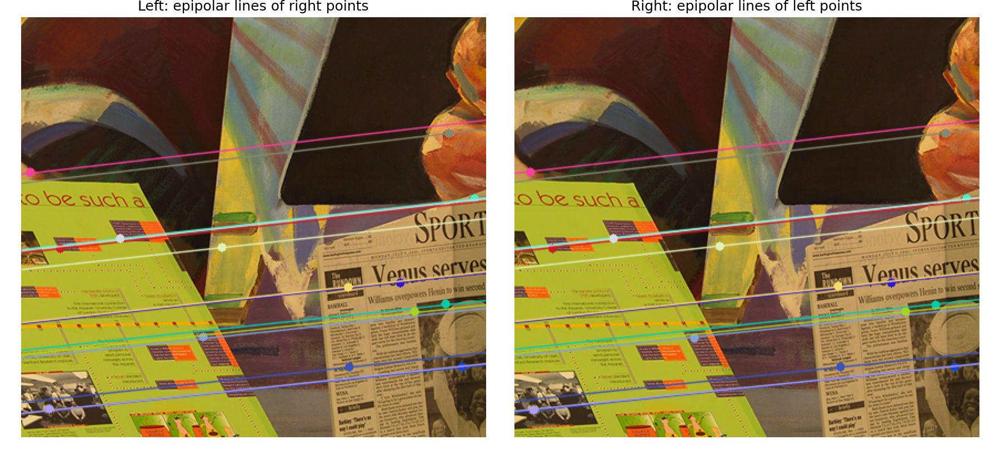

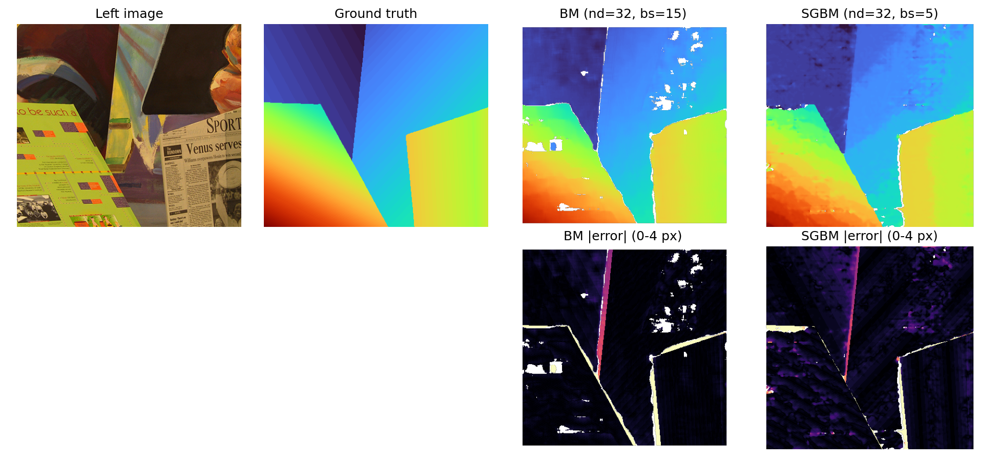

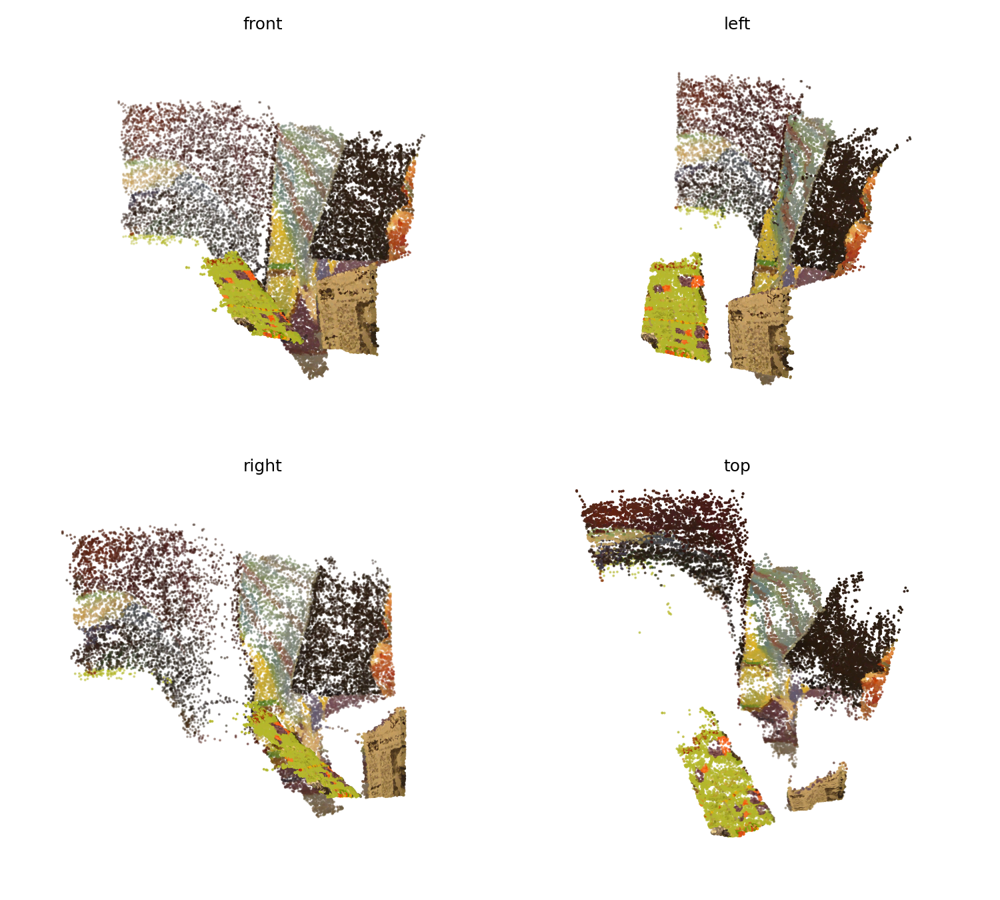

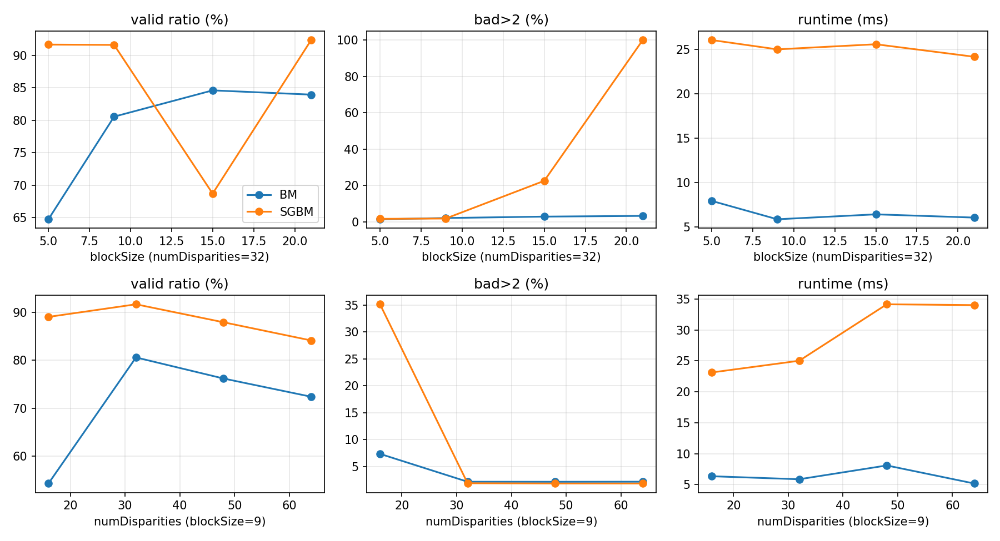

In [4]:
from IPython.display import display, Image
for name in ['epipolar_lines.png', 'disparity_comparison.png', 'pointcloud_views.png', 'chart_stereo_parameters.png']:
    display(Image(filename=f"results/part_b/{name}", width=1000))

## Part C — Ghép ảnh panorama
So sánh SIFT/ORB, KNN + ratio test, homography RANSAC và feathering. Cảnh phẳng hoặc quay thuần cho homography; công thức H = K R K⁻¹ chỉ dùng cho quay thuần với cùng nội tại.

**Bonus — multi-band (Laplacian pyramid) blending:** so sánh seam cứng, feathering và multi-band với 0/2/4/6 tầng pyramid (seam gradient, độ sắc nét vùng chồng lấn, thời gian) và phóng to vùng bóng mờ / seam.

In [5]:
import time
from pathlib import Path
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# detector -> (hàm tạo, khoảng cách dùng khi so khớp): SIFT có descriptor số thực (L2), ORB nhị phân (Hamming)
DETECTORS = {"SIFT": (cv2.SIFT_create, cv2.NORM_L2),
             "ORB": (lambda: cv2.ORB_create(nfeatures=5000), cv2.NORM_HAMMING)}
RATIO = 0.75                       # Lowe ratio test
THRESHOLDS = [1, 3, 5, 10]         # các ngưỡng RANSAC (px) cần so sánh
PANO_THRESHOLD = 3                 # ngưỡng dùng để dựng panorama
MIN_INLIERS = 10                   # ít hơn số này coi như cặp ảnh ghép thất bại
MAX_WIDTH = 1000
MAX_CANVAS_PIXELS = 30_000_000     # canvas lớn hơn mức này: ảnh ngoài bị kéo giãn quá mức (xoay tổng cộng quá rộng)
# Bonus: multi-band (Laplacian pyramid) blending
BLEND_DETECTOR = "SIFT"            # detector dùng cho thí nghiệm blending
PYR_LEVELS = [0, 2, 4, 6]          # số tầng pyramid cần so sánh (0 = seam cứng, không trộn)
BLEND_LEVELS = 6                   # số tầng cho panorama multi-band cuối cùng
CROP = 400                         # cạnh (px) của các vùng phóng to
def match_pair(des_a, des_b, norm):
    """KNN (k=2) matches from image a to image b that pass Lowe's ratio test."""
    if des_a is None or des_b is None or len(des_b) < 2:
        return []
    knn = cv2.BFMatcher(norm).knnMatch(des_a, des_b, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]
def find_homography(src, dst, thresh):
    """RANSAC homography src -> dst; returns H, the inlier mask and the inlier RMSE."""
    if len(src) < 4:
        return None, np.zeros(len(src), bool), np.nan
    cv2.setRNGSeed(42)                                         # fixed seed for reproducibility
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, thresh)
    if H is None:
        return None, np.zeros(len(src), bool), np.nan
    inl = mask.ravel().astype(bool)
    proj = cv2.perspectiveTransform(src[inl].reshape(-1, 1, 2), H).reshape(-1, 2)
    rmse = np.sqrt(np.mean(np.sum((proj - dst[inl]) ** 2, axis=1)))   # sqrt(mean ||x' - H x||^2)
    return H, inl, rmse
def warp_images(images, pair_H):
    """Warp all images into the frame of the middle image on a common canvas.
    pair_H[i] maps image i+1 -> i (chained to the right, inverted to the left)."""
    n, ref = len(images), len(images) // 2
    H = [None] * n
    H[ref] = np.eye(3)
    for i in range(ref + 1, n):
        H[i] = H[i - 1] @ pair_H[i - 1]                       # i -> i-1 -> ... -> ref
    for i in range(ref - 1, -1, -1):
        H[i] = H[i + 1] @ np.linalg.inv(pair_H[i])            # i -> i+1 -> ... -> ref
    corners = []
    for im, Hi in zip(images, H):
        h, w = im.shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        corners.append(cv2.perspectiveTransform(c, Hi).reshape(-1, 2))
    corners = np.vstack(corners)
    x0, y0 = np.floor(corners.min(axis=0))
    x1, y1 = np.ceil(corners.max(axis=0))
    size = (int(x1 - x0), int(y1 - y0))
    if size[0] * size[1] > MAX_CANVAS_PIXELS:
        raise ValueError(f"canvas {size[0]}x{size[1]} px is too large (total rotation too wide for a planar panorama)")
    T = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]])
    warped = [cv2.warpPerspective(im, T @ Hi, size) for im, Hi in zip(images, H)]
    # valid-pixel masks, eroded by 1 px to drop border pixels mixed with black
    masks = [cv2.erode(cv2.warpPerspective(np.full(im.shape[:2], 255, np.uint8), T @ Hi, size,
                                           flags=cv2.INTER_NEAREST), np.ones((3, 3), np.uint8))
             for im, Hi in zip(images, H)]
    return warped, masks
def blend_feather(warped, masks):
    """Feathering: weighted mean, weight = distance to the image border."""
    acc = np.zeros(warped[0].shape, np.float64)
    wsum = np.zeros(warped[0].shape[:2], np.float64)
    for im, m in zip(warped, masks):
        w = cv2.distanceTransform(m, cv2.DIST_L2, 5)
        acc += im * w[..., None]
        wsum += w
    return (acc / np.maximum(wsum, 1e-6)[..., None]).astype(np.uint8)
def seam_masks(masks):
    """Hard seam: each pixel belongs to the image with the largest distance to its border."""
    dist = np.stack([cv2.distanceTransform(m, cv2.DIST_L2, 5) for m in masks])
    owner, covered = dist.argmax(axis=0), dist.max(axis=0) > 0
    return [((owner == k) & covered).astype(np.float32) for k in range(len(masks))]
def fill_outside(im, mask):
    """Fill pixels outside the image with the nearest valid colour (avoids dark borders)."""
    _, labels = cv2.distanceTransformWithLabels((mask == 0).astype(np.uint8), cv2.DIST_L2, 5,
                                                labelType=cv2.DIST_LABEL_PIXEL)
    src = np.flatnonzero(mask.ravel())                         # label k (from 1) = k-th valid pixel in raster order
    return im.reshape(-1, 3)[src[labels.ravel() - 1]].reshape(im.shape)
def gaussian_pyramid(x, levels):
    """[x, pyrDown(x), ...]: levels + 1 tầng, mỗi tầng làm mờ Gaussian rồi giảm một nửa kích thước."""
    pyr = [x]
    for _ in range(levels):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr
def blend_multiband(warped, masks, levels):
    """Multi-band blending: each Laplacian level is blended with the seam mask blurred
    to the same level, then the pyramid is collapsed. levels = 0 gives the hard seam."""
    acc = wsum = None
    for im, m, s in zip(warped, masks, seam_masks(masks)):
        src = fill_outside(im, m) if levels else im            # no filling needed for the hard seam
        g = gaussian_pyramid(src.astype(np.float32), levels)
        lap = [g[l] - cv2.pyrUp(g[l + 1], dstsize=g[l].shape[1::-1]) for l in range(levels)] + [g[-1]]
        w = gaussian_pyramid(s, levels)
        if acc is None:
            acc, wsum = [np.zeros_like(x) for x in lap], [np.zeros_like(x) for x in w]
        for l in range(levels + 1):
            acc[l] += lap[l] * w[l][..., None]
            wsum[l] += w[l]
    # normalise: near the canvas border the blurred masks sum to less than 1
    out = acc[-1] / np.maximum(wsum[-1], 1e-6)[..., None]
    for l in range(levels - 1, -1, -1):
        out = cv2.pyrUp(out, dstsize=acc[l].shape[1::-1]) + acc[l] / np.maximum(wsum[l], 1e-6)[..., None]
    covered = np.any(np.stack(masks) > 0, axis=0)
    return np.where(covered[..., None], np.clip(out, 0, 255), 0).astype(np.uint8)
def blend_quality(pano, masks):
    """Hai chỉ số không cần ground truth, đo trên vùng chồng lấn (pixel thuộc >= 2 ảnh):
    - seam gradient: độ lớn gradient trung bình trên đường seam cứng; càng nhỏ, seam càng khó thấy.
    - overlap sharpness: |Laplacian| trung bình; trộn hai ảnh lệch nhau làm mờ / bóng mờ nên giá trị giảm."""
    gray = cv2.cvtColor(pano, cv2.COLOR_BGR2GRAY).astype(np.float32)
    grad = cv2.magnitude(cv2.Sobel(gray, cv2.CV_32F, 1, 0), cv2.Sobel(gray, cv2.CV_32F, 0, 1))
    overlap = (np.stack(masks) > 0).sum(axis=0) >= 2
    owner = np.argmax(np.stack(seam_masks(masks)), axis=0).astype(np.uint8)
    seam = overlap & (cv2.morphologyEx(owner, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0)
    return {"seam gradient": grad[seam].mean(), "overlap sharpness": np.abs(cv2.Laplacian(gray, cv2.CV_32F))[overlap].mean()}
def blending_study(name, warped, masks, feather, feather_ms, out_dir):
    """Bonus: so sánh seam cứng, feathering và multi-band blending với số tầng pyramid khác nhau;
    lưu CSV, panorama multi-band và hình phóng to hai vùng khác nhau nhiều nhất."""
    rows, panos = [], {"Feathering": feather}
    rows.append({"method": "Feathering", "levels": "-", **blend_quality(feather, masks), "blend_ms": feather_ms})
    for lv in PYR_LEVELS:
        t0 = time.perf_counter()
        pano = blend_multiband(warped, masks, lv)
        ms = (time.perf_counter() - t0) * 1000
        label = "Hard seam" if lv == 0 else "Multi-band"
        rows.append({"method": label, "levels": lv, **blend_quality(pano, masks), "blend_ms": ms})
        if lv in (0, BLEND_LEVELS):
            panos["Hard seam" if lv == 0 else f"Multi-band ({lv} levels)"] = pano
    df = pd.DataFrame(rows)
    sharp0 = df.loc[df.method == "Hard seam", "overlap sharpness"].iloc[0]
    df["sharpness vs hard seam (%)"] = 100 * df["overlap sharpness"] / sharp0
    df.round(3).to_csv(out_dir / "blending_metrics.csv", index=False)
    multi = panos[f"Multi-band ({BLEND_LEVELS} levels)"]
    cv2.imwrite(str(out_dir / f"panorama_{name}_multiband.jpg"), multi)
    # Vùng phóng to: (1) feathering khác multi-band nhiều nhất -> bóng mờ của vật chuyển động;
    # (2) seam cứng khác multi-band nhiều nhất -> bậc sáng ở seam. Vùng (2) không chồng lên vùng (1).
    crops, used = [], np.zeros(multi.shape[:2], bool)
    for a in (panos["Feathering"], panos["Hard seam"]):
        diff = cv2.blur(np.abs(a.astype(np.float32) - multi).mean(axis=2), (CROP, CROP))
        diff[used] = 0
        y, x = np.unravel_index(np.argmax(diff), diff.shape)
        y0, x0 = max(0, y - CROP // 2), max(0, x - CROP // 2)
        crops.append((y0, x0))
        used[max(0, y0 - CROP):y0 + 2 * CROP, max(0, x0 - CROP):x0 + 2 * CROP] = True
    fig, axes = plt.subplots(len(crops), len(panos), figsize=(3.4 * len(panos), 3.9 * len(crops)), squeeze=False)
    for r, (y0, x0) in enumerate(crops):
        for c, (title, p) in enumerate(panos.items()):
            axes[r, c].imshow(cv2.cvtColor(p[y0:y0 + CROP, x0:x0 + CROP], cv2.COLOR_BGR2RGB))
            axes[r, c].set_title(f"{title}\n(x={x0}, y={y0})" if c == 0 else title, fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / "blending_comparison.png", dpi=150)
    plt.close(fig)
    # Toàn cảnh feathering và multi-band đặt chồng lên nhau
    fig, axes = plt.subplots(2, 1, figsize=(10, 8.4))
    for ax, (title, p) in zip(axes, [("Feathering", feather), (f"Multi-band ({BLEND_LEVELS} levels)", multi)]):
        ax.imshow(cv2.cvtColor(p, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{name} + {title}")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / "panorama_blending.png", dpi=150)
    plt.close(fig)
    return df
def run_detector(name, images, out_dir):
    """Toàn bộ pipeline cho một detector: trả về dòng CSV theo cặp / ngưỡng, dòng tổng và panorama."""
    make, norm = DETECTORS[name]
    det = make()
    grays = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in images]
    det.detectAndCompute(grays[0], None)                       # chạy khởi động: lần gọi đầu tiên luôn chậm hơn
    t0 = time.perf_counter()
    feats = [det.detectAndCompute(g, None) for g in grays]
    t_detect = (time.perf_counter() - t0) * 1000
    rows, pair_H, t_match, t_ransac, ok = [], [], 0.0, 0.0, True
    for i in range(len(images) - 1):
        (kp_a, des_a), (kp_b, des_b) = feats[i], feats[i + 1]
        t0 = time.perf_counter()
        good = match_pair(des_a, des_b, norm)
        t_match += (time.perf_counter() - t0) * 1000
        dst = np.float32([kp_a[m.queryIdx].pt for m in good])  # điểm trong ảnh i
        src = np.float32([kp_b[m.trainIdx].pt for m in good])  # điểm trong ảnh i+1 -> H: ảnh i+1 -> ảnh i
        for t in THRESHOLDS:
            t0 = time.perf_counter()
            H, inl, rmse = find_homography(src, dst, t)
            ms = (time.perf_counter() - t0) * 1000
            rows.append({"row_type": "pair", "detector": name, "pair": f"{i + 1}-{i + 2}", "ransac_thresh_px": t,
                         "keypoints_img1": len(kp_a), "keypoints_img2": len(kp_b), "initial_matches": len(good),
                         "inliers": int(inl.sum()), "inlier_ratio_pct": 100 * inl.mean() if len(good) else 0.0,
                         "rmse_px": rmse, "ransac_ms": ms})
            if t == PANO_THRESHOLD:
                t_ransac += ms
                pair_H.append(H)
                save_matches(name, i, images, kp_a, kp_b, good, inl, rows[-1], out_dir)
                if inl.sum() < MIN_INLIERS:                     # cặp ảnh không đủ inlier -> bỏ panorama
                    print(f"[Part C] {name}: pair {i + 1}-{i + 2} has only {inl.sum()} inliers, panorama skipped")
                    ok = False
    pano3 = [r for r in rows if r["ransac_thresh_px"] == PANO_THRESHOLD]
    inliers = sum(r["inliers"] for r in pano3)
    total = {"row_type": "total", "detector": name, "pair": "all", "ransac_thresh_px": PANO_THRESHOLD,
             "keypoints_per_image": np.mean([len(kp) for kp, _ in feats]),
             "initial_matches": sum(r["initial_matches"] for r in pano3), "inliers": inliers,
             "inlier_ratio_pct": 100 * inliers / max(1, sum(r["initial_matches"] for r in pano3)),
             # RMSE chung của mọi inlier trên 3 cặp ảnh
             "rmse_px": np.sqrt(sum(r["inliers"] * r["rmse_px"] ** 2 for r in pano3) / max(1, inliers)),
             "detect_ms": t_detect, "match_ms": t_match, "ransac_ms": t_ransac, "status": "ok" if ok else "skipped"}
    if not ok:
        return rows, total, None
    t0 = time.perf_counter()
    try:
        warped, masks = warp_images(images, pair_H)
    except ValueError as e:                                    # chuỗi homography kéo giãn quá mức -> bỏ panorama
        print(f"[Part C] {name}: {e}, panorama skipped")
        total["status"] = "skipped"
        return rows, total, None
    total["warp_ms"] = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    pano = blend_feather(warped, masks)
    total["blend_ms"] = (time.perf_counter() - t0) * 1000
    total["total_stitching_ms"] = t_detect + t_match + t_ransac + total["warp_ms"] + total["blend_ms"]
    cv2.imwrite(str(out_dir / f"panorama_{name}.jpg"), pano)
    save_keypoints(name, images, feats, out_dir)
    if name == BLEND_DETECTOR:
        print(blending_study(name, warped, masks, pano, total["blend_ms"], out_dir).round(2).to_string(index=False))
    return rows, total, pano
def save_keypoints(name, images, feats, out_dir):
    """Hình keypoint của detector trên cả 4 ảnh."""
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.8))
    for ax, im, (kp, _) in zip(axes, images, feats):
        ax.imshow(cv2.cvtColor(cv2.drawKeypoints(im, kp, None, color=(0, 255, 0)), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{name}: {len(kp)} keypoints", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / f"keypoints_{name}.png", dpi=150)
    plt.close(fig)
def save_matches(name, i, images, kp_a, kp_b, good, inl, row, out_dir):
    """Vẽ các inlier match (sau RANSAC) giữa ảnh i và ảnh i+1; vẽ tối đa ~150 đường cho dễ nhìn."""
    keep = np.zeros(len(good), np.uint8)
    keep[np.flatnonzero(inl)[::max(1, int(inl.sum()) // 150)]] = 1
    vis = cv2.drawMatches(images[i], kp_a, images[i + 1], kp_b, good, None, matchColor=(0, 255, 0),
                          matchesMask=keep.tolist(), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    fig = plt.figure(figsize=(10, 7.5))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f"{name}, images {i + 1}-{i + 2}: {row['initial_matches']} matches, {row['inliers']} inliers "
              f"({row['inlier_ratio_pct']:.1f}%), RMSE {row['rmse_px']:.2f} px", fontsize=10)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / f"matches_{name}_pair{i + 1}{i + 2}.png", dpi=150)
    plt.close(fig)
def save_chart(pairs, out_dir):
    """Tỉ lệ inlier và RMSE theo ngưỡng RANSAC, mỗi cặp ảnh một cột, mỗi detector một đường."""
    names = list(dict.fromkeys(pairs["pair"]))
    fig, axes = plt.subplots(2, len(names), figsize=(3.6 * len(names), 6), sharey="row")
    for c, pair in enumerate(names):
        for r, (col, label) in enumerate([("inlier_ratio_pct", "Inlier ratio (%)"), ("rmse_px", "Inlier RMSE (px)")]):
            for det in DETECTORS:
                s = pairs[(pairs["detector"] == det) & (pairs["pair"] == pair)]
                axes[r, c].plot(s["ransac_thresh_px"], s[col], marker="o", label=det)
            axes[r, c].set_xticks(THRESHOLDS)
            axes[r, c].grid(alpha=0.3)
            axes[r, 0].set_ylabel(label)
        axes[0, c].set_title(f"Pair {pair}")
        axes[1, c].set_xlabel("RANSAC threshold (px)")
    axes[0, 0].legend()
    plt.tight_layout()
    plt.savefig(out_dir / "chart_ransac_threshold.png", dpi=150)
    plt.close(fig)
def run_stitching():
    out_dir = Path("results/part_c")
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = sorted(p for p in Path("data/part_c").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    images = []
    for p in paths:
        im = cv2.imread(str(p))
        if im.shape[1] > MAX_WIDTH:                           # ảnh điện thoại lớn -> thu về rộng 1000 px
            im = cv2.resize(im, None, fx=MAX_WIDTH / im.shape[1], fy=MAX_WIDTH / im.shape[1],
                            interpolation=cv2.INTER_AREA)
        images.append(im)
    pair_rows, totals, panos = [], [], {}
    for name in DETECTORS:
        rows, total, pano = run_detector(name, images, out_dir)
        pair_rows += rows
        totals.append(total)
        if pano is not None:
            panos[name] = pano
    pairs, summary = pd.DataFrame(pair_rows), pd.DataFrame(totals)
    pd.concat([pairs, summary]).round(4).to_csv(out_dir / "stitching_metrics.csv", index=False)
    summary.round(3).to_csv(out_dir / "stitching_summary.csv", index=False)
    save_chart(pairs, out_dir)
    print(summary.round(2).to_string(index=False))
    if not panos:
        return
    # Panorama của các detector đặt chồng lên nhau để so sánh
    fig, axes = plt.subplots(len(panos), 1, figsize=(10, 4.2 * len(panos)), squeeze=False)
    for ax, (name, pano) in zip(axes[:, 0], panos.items()):
        ax.imshow(cv2.cvtColor(pano, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{name} + feathering")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(out_dir / "panorama_comparison.png", dpi=150)
    plt.close(fig)
run_stitching()

    method levels  seam gradient  overlap sharpness  blend_ms  sharpness vs hard seam (%)
Feathering      -      44.290001              11.48   1963.05                   86.320000
 Hard seam      0      72.690002              13.30   2853.53                  100.000000
Multi-band      2      52.470001              13.27   7181.54                   99.720001
Multi-band      4      50.650002              13.27   7102.55                   99.769997
Multi-band      6      50.669998              13.28   7049.37                   99.809998


row_type detector pair  ransac_thresh_px  keypoints_per_image  initial_matches  inliers  inlier_ratio_pct  rmse_px  detect_ms  match_ms  ransac_ms status  warp_ms  blend_ms  total_stitching_ms
   total     SIFT  all                 3              8350.75             3213     1873             58.29     1.48    1058.51    832.44       9.49     ok   281.77   1963.05             4145.26
   total      ORB  all                 3              5000.00             1622     1079             66.52     1.49     118.81    340.68       7.12     ok   349.18   2538.82             3354.62


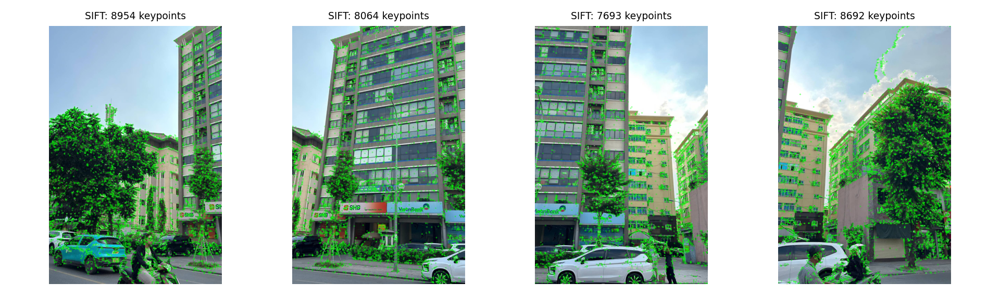

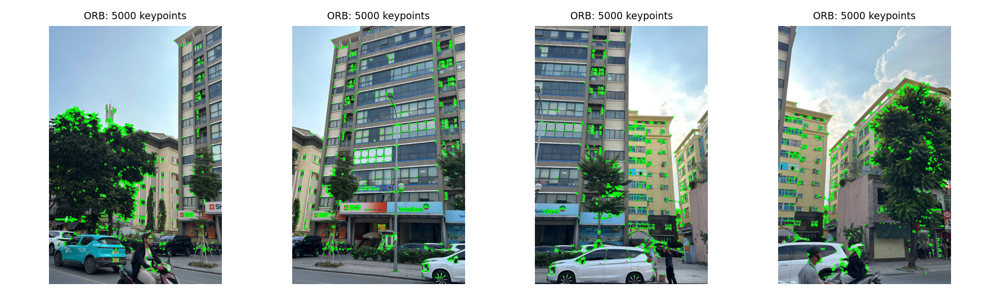

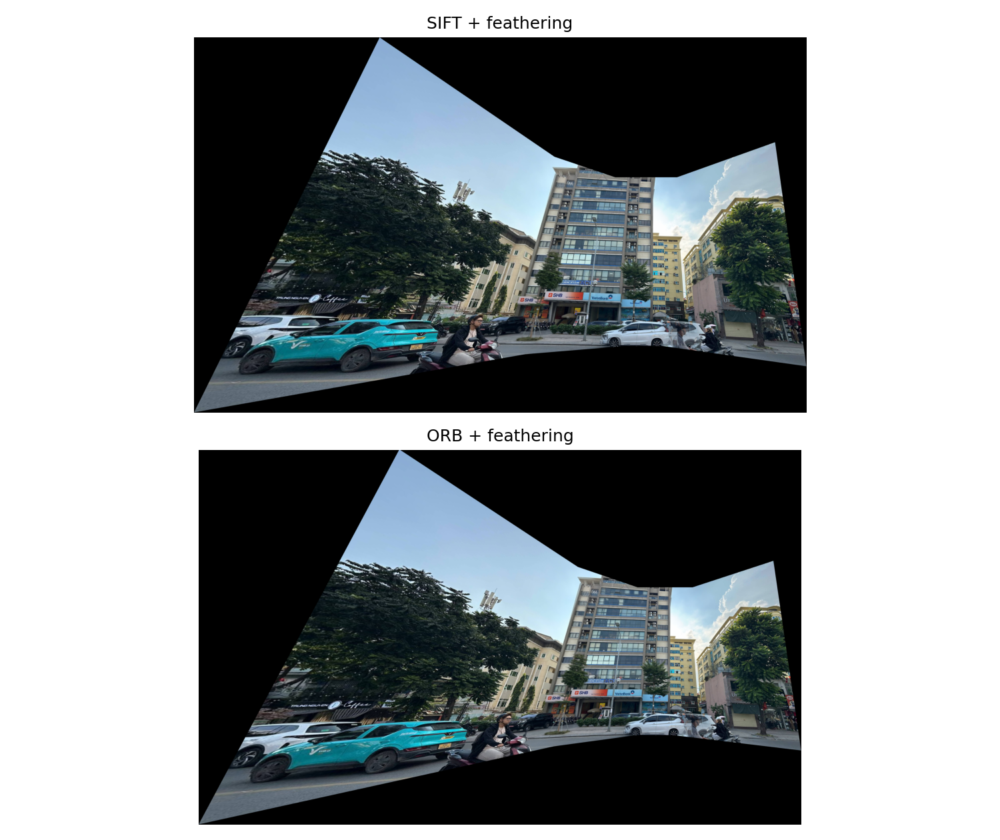

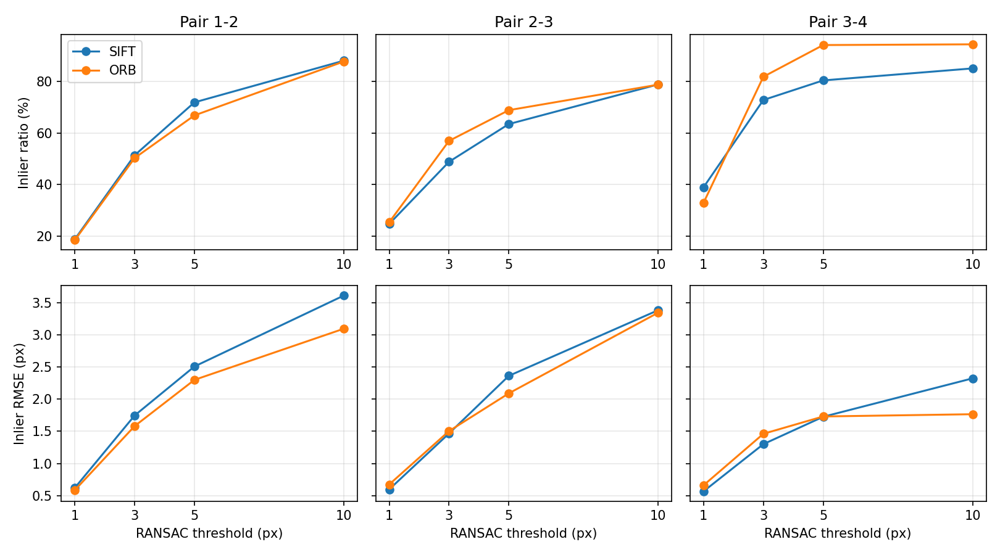

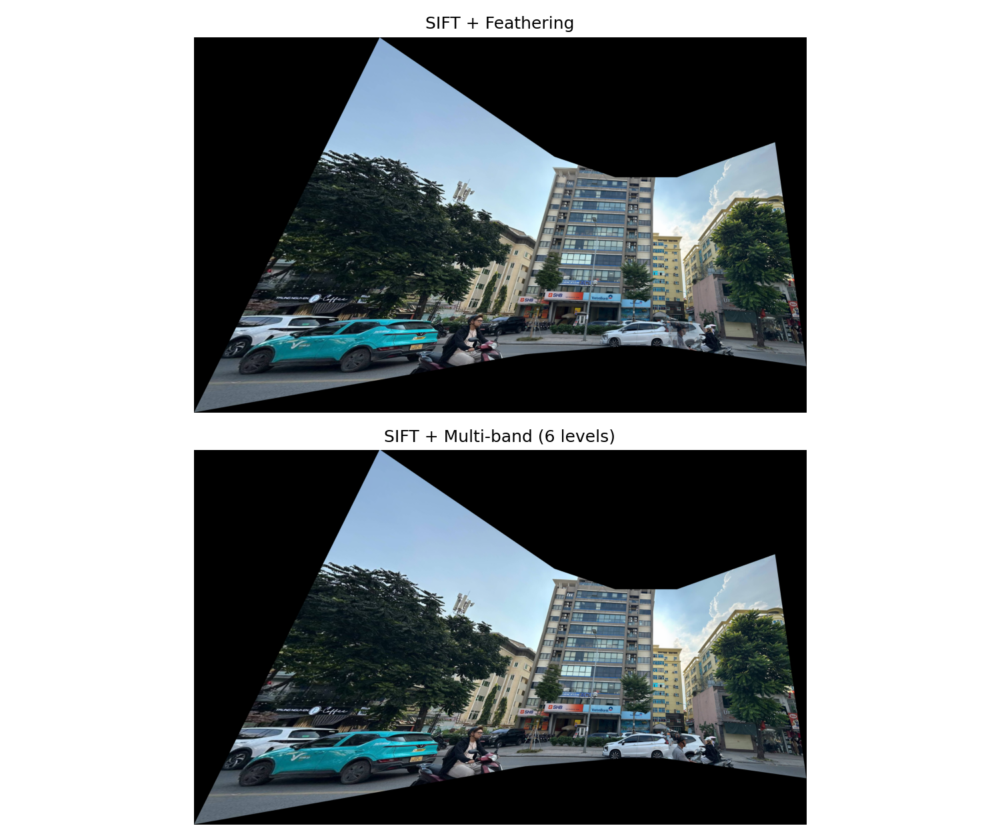

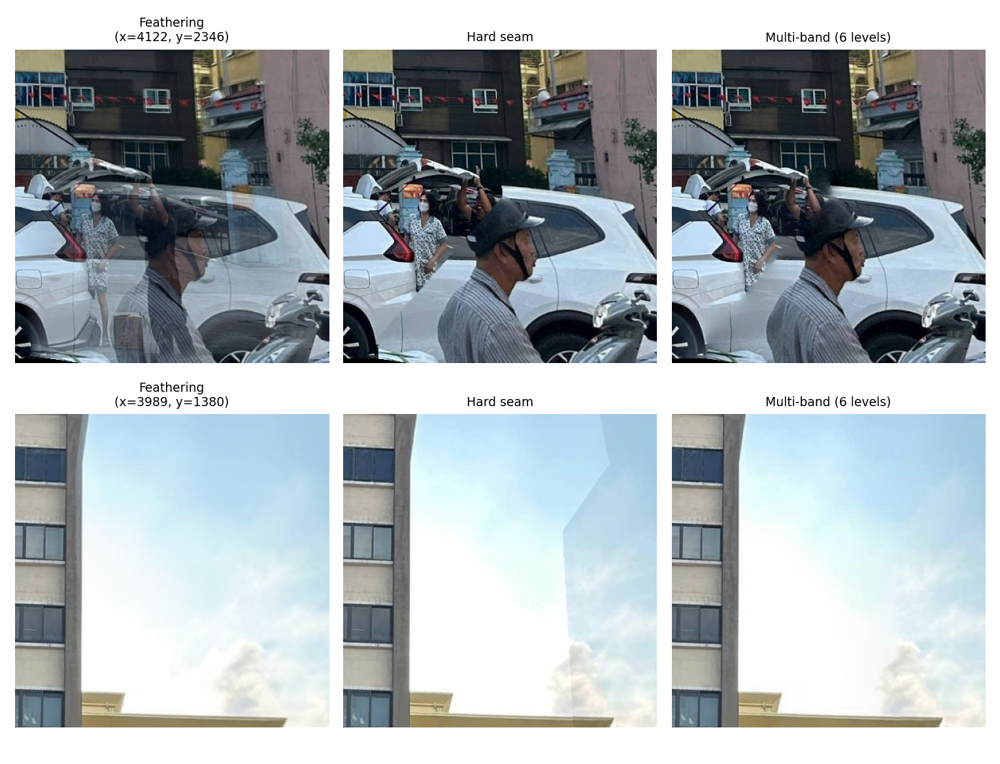

In [6]:
from IPython.display import display, Image
for name in ['keypoints_SIFT.png', 'keypoints_ORB.png', 'panorama_comparison.png', 'chart_ransac_threshold.png', 'panorama_blending.png', 'blending_comparison.png']:
    display(Image(filename=f"results/part_c/{name}", width=1000))